# Dinâmica da Criminalidade no Rio de Janeiro: Uma Análise Integrada Sobre Segurança Pública

##### *Análise Exploratória de Dados e Visualização*
##### *FGV EMAp - Escola de Matemática Aplicada | Semestre 2026.2*
##### *Professor:* João Rulff
##### *Autores:*
##### Josué Santos de Oliveira da Silva 
##### Leonardo Cardia Bicca
##### Luigi Parmeggiani Porto

##### Repositório do Projeto:

# *Introdução*

    O estado do Rio de Janeiro vivencia, há décadas, um dos cenários de segurança pública mais desafiadores e militarizados da América Latina. O presente artigo investiga a arquitetura espaço-temporal da violência letal fluminense a partir do cruzamento de 14 bases de microdados abertos fornecidas pelo Instituto de Segurança Pública (ISP-RJ), cobrindo o período longitudinal de 2003 a 2024. Estruturado em torno de sete perguntas de domínio articuladas lógica e metodologicamente, o estudo aborda desde a substituição tecnológica nos arsenais do crime organizado até as dinâmicas territoriais de letalidade policial e violência de gênero.

# *O Que o Leitor deve Saber:*

1. Sobre os dados: Os dados têm origem no Instituto de Segurança Pública do Estado do Rio de Janeiro (ISP-RJ) e estão
estruturados em um conjunto de bases de dados abertas de frequências mensal e anual. A coleta e agregação
originais são feitas através dos registros de ocorrência das delegacias do estado.
Utilizaremos diversas tabelas relacionais que cobrem diferentes dimensões da segurança. As variáveis
mais relevantes para a análise incluem os recortes temporais e geográficos, tipificações de armas apreendidas
(com destaque para fuzis) e contagens e taxas (por 100 mil habitantes) de crimes contra a vida. Utilizaremos
também a tabela de relação CISP-AISP-RISP para realizar cruzamentos de dados espaciais entre os níveis
de delegacia, município e estado.


2. Siglas:
CISP: A Circunscrição Integrada de Segurança Pública é a área territorial que coincide com a jurisdição de uma delegacia distrital da Polícia Civil (SEPOL) e a subárea correspondente de uma companhia da Polícia Militar (SEPM).
AISP: A Área Integrada de Segurança Pública é uma divisão territorial que alinha a atuação da Polícia Militar (PMERJ) e da Polícia Civil (PCERJ) na mesma região para combater a criminalidade de forma conjunta.
RISP: A Região Integrada de Segurança Pública une os comandos intermediários das polícias, ou seja, os Departamentos de Polícia de Área (DPA) da Polícia Civil e os Comandos de Policiamento de Área (CPA) da Polícia Militar.

# Importação das Bibliotecas Utilizadas:

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.io as pio
import plotly.express as px
import tempfile
import os
import sys
import warnings
import requests
from matplotlib.patches import Patch
print(f"Pandas {pd.__version__} | NumPy {np.__version__} | GeoPandas {gpd.__version__} | Matplotlib | Seaborn {sns.__version__}")

Pandas 3.0.3 | NumPy 2.4.6 | GeoPandas 1.2.0 | Matplotlib | Seaborn 0.13.2


# Carregamento de Dados(Do repositório do github "https://github.com/josue-fgv/AEDV-A2-") 

In [3]:
from io import BytesIO

url = "https://api.github.com/repos/josue-fgv/AEDV-A2-/contents/Projeto/Datas"

resposta = requests.get(url, timeout=30)

print("Status da API:", resposta.status_code)

resposta.raise_for_status()

prefixo = "br_rj_isp_estatisticas_seguranca_"

dataframes = {}

for arquivo in resposta.json():

    if arquivo["name"].endswith(".csv"):

        nome = arquivo["name"].removesuffix(".csv").removeprefix(prefixo)

        conteudo = requests.get(arquivo["download_url"], timeout=60)
        conteudo.raise_for_status()

        dataframes[nome] = pd.read_csv(BytesIO(conteudo.content))

        print(f"{nome}: importado com sucesso!")

print(f"\nTotal: {len(dataframes)} DataFrames")

Status da API: 200
PopulacaoEvolucaoMensalCisp: importado com sucesso!
armas_apreendidas_mensal: importado com sucesso!
armas_fogo_apreendidas_mensal: importado com sucesso!
evolucao_mensal_cisp: importado com sucesso!
evolucao_mensal_municipio: importado com sucesso!
evolucao_mensal_uf: importado com sucesso!
evolucao_mensal_upp: importado com sucesso!
evolucao_policial_morto_servico_mensal: importado com sucesso!
feminicidio_mensal_cisp: importado com sucesso!
relacao_cisp_aisp_risp: importado com sucesso!
taxa_evolucao_anual_municipio: importado com sucesso!
taxa_evolucao_anual_uf: importado com sucesso!
taxa_evolucao_mensal_municipio: importado com sucesso!
taxa_evolucao_mensal_uf: importado com sucesso!
taxa_letalidade: importado com sucesso!

Total: 15 DataFrames


In [4]:
(
    df_armas,
    df_armas_fogo,
    df_cisp_mensal,
    df_mun_mensal,
    df_evol_uf,
    df_evol_upp,
    df_policial,
    df_fem_cisp,
    df_rel,
    df_taxa_anual_municipio,
    df_taxa_anual_uf,
    df_taxa_mun_mensal,
    df_taxa_mensal_uf,
    df_letalidade
) = (
    dataframes["armas_apreendidas_mensal"],
    dataframes["armas_fogo_apreendidas_mensal"],
    dataframes["evolucao_mensal_cisp"],
    dataframes["evolucao_mensal_municipio"],
    dataframes["evolucao_mensal_uf"],
    dataframes["evolucao_mensal_upp"],
    dataframes["evolucao_policial_morto_servico_mensal"],
    dataframes["feminicidio_mensal_cisp"],
    dataframes["relacao_cisp_aisp_risp"],
    dataframes["taxa_evolucao_anual_municipio"],
    dataframes["taxa_evolucao_anual_uf"],
    dataframes["taxa_evolucao_mensal_municipio"],
    dataframes["taxa_evolucao_mensal_uf"],
    dataframes["taxa_letalidade"]
)


# Visualizando os Dados 

In [130]:
df_armas.head()

,ano,mes,id_cisp,id_aisp,id_risp,quantidade_arma_fabricacao_caseira,quantidade_carabina,quantidade_espingarda,quantidade_fuzil,quantidade_garrucha,...,quantidade_simulacro_outros,quantidade_simulacro_paintball,quantidade_simulacro_pistola,quantidade_simulacro_revolver,quantidade_simulacro_submetralhadora,quantidade_artefato_explosivo_total,quantidade_simulacro_total,quantidade_arma_fogo_total,quantidade_arma_branca_total,quantidade_municao_total
0,2007,3,16,31,2,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN
1,2007,6,16,31,2,0,0,0,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5,NaN,NaN
2,2007,3,27,41,2,0,0,1,3,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24,NaN,NaN
3,2007,2,32,18,2,0,0,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,7,NaN,NaN
4,2007,2,37,17,1,0,0,1,0,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,NaN,NaN


In [131]:
df_armas_fogo.head()

,ano,mes,id_municipio,id_cisp,id_aisp,id_risp,quantidade_arma_fogo_apreendida
0,2003,3,3304557,1,5,1,1
1,2003,1,3304557,1,5,1,4
2,2003,6,3304557,1,5,1,3
3,2003,4,3304557,1,5,1,2
4,2003,11,3304557,1,5,1,1


In [132]:
df_cisp_mensal.head()

,ano,mes,id_cisp,id_aisp,id_risp,id_municipio,regiao,quantidade_homicidio_doloso,quantidade_latrocinio,quantidade_lesao_corporal_morte,...,quantidade_cmp,quantidade_cmba,quantidade_ameaca,quantidade_pessoas_desaparecidas,quantidade_encontro_cadaver,quantidade_encontro_ossada,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico,quantidade_registro_ocorrencia,tipo_fase
0,2003,9,1,5,1,3304557,Capital,1,0,0,...,NaN,NaN,19,1,0,0,0,0,656,Consolidado com errata
1,2003,12,1,5,1,3304557,Capital,1,0,0,...,NaN,NaN,21,4,1,0,0,0,725,Consolidado com errata
2,2003,6,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,21,3,0,0,0,0,587,Consolidado com errata
3,2003,11,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,29,0,0,0,0,0,760,Consolidado com errata
4,2003,3,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,20,1,0,0,0,0,573,Consolidado com errata


In [133]:
df_evol_uf.head()

,ano,mes,quantidade_homicidio_doloso,quantidade_latrocinio,quantidade_lesao_corporal_morte,quantidade_crimes_violentos_letais_intencionais,quantidade_homicidio_intervencao_policial,quantidade_letalidade_violenta,quantidade_tentativa_homicidio,quantidade_lesao_corporal_dolosa,...,quantidade_cmp,quantidade_cmba,quantidade_ameaca,quantidade_pessoa_desaparecida,quantidade_encontro_cadaver,quantidade_encontro_ossada,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico,quantidade_registro_ocorrencia,tipo_fase
0,2010,1,447,19,6.0,472.0,77.0,549,377,7716,...,695.0,43.0,6868.0,481.0,69,2.0,3.0,3.0,56534.0,Consolidado com errata
1,1991,4,634,20,NaN,NaN,NaN,654,200,3211,...,NaN,NaN,NaN,NaN,140,NaN,NaN,NaN,NaN,Consolidado com errata
2,1991,5,650,20,NaN,NaN,NaN,670,146,3051,...,NaN,NaN,NaN,NaN,78,NaN,NaN,NaN,NaN,Consolidado com errata
3,1991,2,732,17,NaN,NaN,NaN,749,175,3421,...,NaN,NaN,NaN,NaN,209,NaN,NaN,NaN,NaN,Consolidado com errata
4,1991,1,657,15,NaN,NaN,NaN,672,162,3051,...,NaN,NaN,NaN,NaN,217,NaN,NaN,NaN,NaN,Consolidado com errata


In [134]:
df_evol_upp.head()

,ano,mes,id_upp,nome,quantidade_homicidio_doloso,quantidade_latrocinio,quantidade_lesao_corporal_morte,quantidade_homicidio_intervencao_policial,quantidade_tentativa_homicidio,quantidade_lesao_corporal_dolosa,...,quantidade_estelionato,quantidade_apreensao_droga,quantidade_registro_veiculo_recuperado,quantidade_ameaca,quantidade_pessoa_desaparecida,quantidade_encontro_cadaver,quantidade_encontro_ossada,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico,quantidade_registro_ocorrencia
0,2007,4,33,Cerro-Corá,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1
1,2007,4,36,Camarista Méier,0,0,0,0,0,1,...,0,1,0,2,0,0,0,0,0,18
2,2007,8,13,São João / Matriz / Queto,1,0,0,0,0,1,...,1,1,0,0,0,0,0,0,0,11
3,2007,9,34,Arará / Mandela,0,0,0,0,0,2,...,0,0,0,0,0,0,0,0,0,4
4,2007,11,18,Macacos,0,0,0,0,0,3,...,1,0,2,1,0,0,0,0,0,31


In [135]:
df_fem_cisp.head()

,ano,mes,id_cisp,id_aisp,id_risp,id_municipio,quantidade_morte_feminicidio,quantidade_tentativa_feminicidio,tipo_fase
0,2016,12,1,5,1,3304557,0,0,Consolidado com errata
1,2016,11,1,5,1,3304557,0,0,Consolidado com errata
2,2016,12,10,2,1,3304557,0,0,Consolidado com errata
3,2016,11,10,2,1,3304557,0,0,Consolidado com errata
4,2016,11,100,37,5,3304110,0,0,Consolidado com errata


In [136]:
df_letalidade.head()

,ano,regiao,delito,contagem_delito,populacao,taxa_cem_mil_habitantes
0,2000,Baixada Fluminense,Morte por Intervencao do Agente do Estado,85.000,3382829,2.5
1,2000,Baixada Fluminense,Homicídio Doloso,1.757,3382829,51.9
2,2000,Baixada Fluminense,Letalidade Violenta,1.915,3382829,56.6
3,2001,Baixada Fluminense,Morte por Intervencao do Agente do Estado,133.000,3408272,3.9
4,2001,Baixada Fluminense,Homicídio Doloso,1.820,3408272,53.4


In [137]:
df_mun_mensal.head()

,ano,mes,id_municipio,regiao,quantidade_homicidio_doloso,quantidade_latrocinio,quantidade_lesao_corporal_morte,quantidade_crimes_violentos_letais_intencionais,quantidade_homicidio_intervencao_policial,quantidade_letalidade_violenta,...,quantidade_cmp,quantidade_cmba,quantidade_ameaca,quantidade_pessoas_desaparecida,quantidade_encontro_cadaver,quantidade_encontro_ossada,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico,quantidade_registro_ocorrencia,tipo_fase
0,2024,8,3300100,Interior,0,0,0,0,3,3,...,14,2,48,8,0,0,0,0,543,Consolidado com errata
1,2024,10,3300100,Interior,0,0,0,0,0,0,...,8,0,75,6,1,0,0,0,555,Consolidado com errata
2,2024,7,3300100,Interior,0,0,0,0,2,2,...,13,3,48,2,0,0,0,0,496,Consolidado com errata
3,2022,8,3300100,Interior,0,0,0,0,5,5,...,12,0,74,3,2,0,0,0,552,Consolidado com errata
4,2026,5,3300100,Interior,0,0,0,0,1,1,...,20,3,63,6,0,0,0,0,702,Consolidado com errata


In [138]:
df_policial.head()

,ano,mes,id_cisp,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico
0,2003,1,27,0,0
1,2003,1,37,0,0
2,2003,1,159,0,0
3,2003,1,165,0,0
4,2003,2,41,0,0


In [139]:
df_rel.head()

,id_risp,id_aisp,id_cisp,id_municipio,unidade_territorial,regiao
0,1,16,38,3304557,Brás de Pina (parte); Cordovil; Jardim América...,Metropolitana
1,1,16,22,3304557,Brás de Pina (parte); Olaria; Penha e Penha Ci...,Metropolitana
2,1,17,37,3304557,Bancários; Cacuia; Cidade Universitária; Cocot...,Metropolitana
3,1,19,12,3304557,Copacabana (parte) e Leme,Metropolitana
4,1,19,13,3304557,Copacabana (parte),Metropolitana


In [140]:
df_taxa_anual_municipio.head()

,ano,id_municipio,regiao,taxa_homicidio_doloso,taxa_latrocinio,taxa_lesao_corporal_morte,taxa_crimes_violentos_letais_intencionais,taxa_homicidio_intervencao_policial,taxa_letalidade_violenta,taxa_tentativa_homicidio,...,taxa_cmp,taxa_cmba,taxa_ameaca,taxa_pessoas_desaparecidas,taxa_encontro_cadaver,taxa_encontro_ossada,taxa_policial_militar_morto_servico,taxa_policial_civil_morto_servico,taxa_registro_ocorrencia,tipo_fase
0,2014,3305109,Baixada Fluminense,45.36,1.09,0.0,46.45,4.99,51.44,29.30,...,60.34,0.22,537.86,60.12,0.87,0.0,0.00,0.0,4711.20,Consolidado com errata
1,2018,3303203,Baixada Fluminense,14.79,0.62,0.0,15.41,0.62,16.02,38.82,...,48.07,4.31,388.86,31.43,1.85,0.0,0.00,0.0,5066.28,Consolidado com errata
2,2020,3301850,Baixada Fluminense,47.24,0.00,0.0,47.24,3.26,50.50,30.95,...,65.16,1.63,293.22,26.06,1.63,0.0,0.00,0.0,2399.49,Consolidado com errata
3,2015,3301702,Baixada Fluminense,35.46,0.91,0.0,36.36,5.21,41.58,36.70,...,88.93,2.04,376.22,36.48,2.04,0.0,4.14,0.0,4280.36,Consolidado com errata
4,2014,3303203,Baixada Fluminense,39.80,1.90,0.0,41.69,0.63,42.32,38.53,...,103.60,0.63,649.40,50.54,1.90,0.0,0.00,0.0,5850.95,Consolidado com errata


In [141]:
df_taxa_anual_uf.head()

,ano,taxa_homicidio_doloso,taxa_latrocinio,taxa_lesao_corporal_morte,taxa_crimes_violentos_letais_intencionais,taxa_homicidio_intervencao_policial,taxa_letalidade_violenta,taxa_tentativa_homicidio,taxa_lesao_corporal_dolosa,taxa_estupro,...,taxa_cmp,taxa_cmba,taxa_ameaca,taxa_pessoas_desaparecidas,taxa_encontro_cadaver,taxa_encontro_ossada,taxa_policial_militar_morto_servico,taxa_policial_civil_morto_servico,taxa_registro_ocorrencia,tipo_fase
0,2023,18.75,0.37,0.23,19.35,4.96,24.31,18.54,353.91,31.48,...,70.13,7.07,365.40,33.11,1.78,0.14,25.16,0.00,4640.78,Consolidado com errata
1,2017,31.98,1.42,0.23,33.63,6.74,40.37,35.89,362.19,29.62,...,101.08,9.97,305.25,27.70,2.25,0.15,66.52,40.04,4489.56,Consolidado com errata
2,2022,17.42,0.36,0.18,17.97,7.57,25.54,20.33,328.14,32.04,...,62.55,4.49,318.33,29.92,2.62,0.15,39.05,23.94,4406.80,Consolidado com errata
3,2021,18.63,0.63,0.25,19.50,7.76,27.27,22.78,296.22,29.26,...,64.12,2.90,287.99,23.15,1.58,0.23,20.17,11.56,3553.48,Consolidado com errata
4,2020,20.41,0.50,0.18,21.09,7.17,28.26,25.06,286.45,27.33,...,68.39,5.19,255.63,19.29,1.64,0.15,31.69,55.84,3368.55,Consolidado com errata


# Perguntas 

## Pergunta 1(Rascunho)


Qual é a evolução histórica do volume absoluto e da taxa (por 100 mil habitantes) de armas de fogo
e fuzis apreendidos no estado do Rio de Janeiro nos últimos anos?

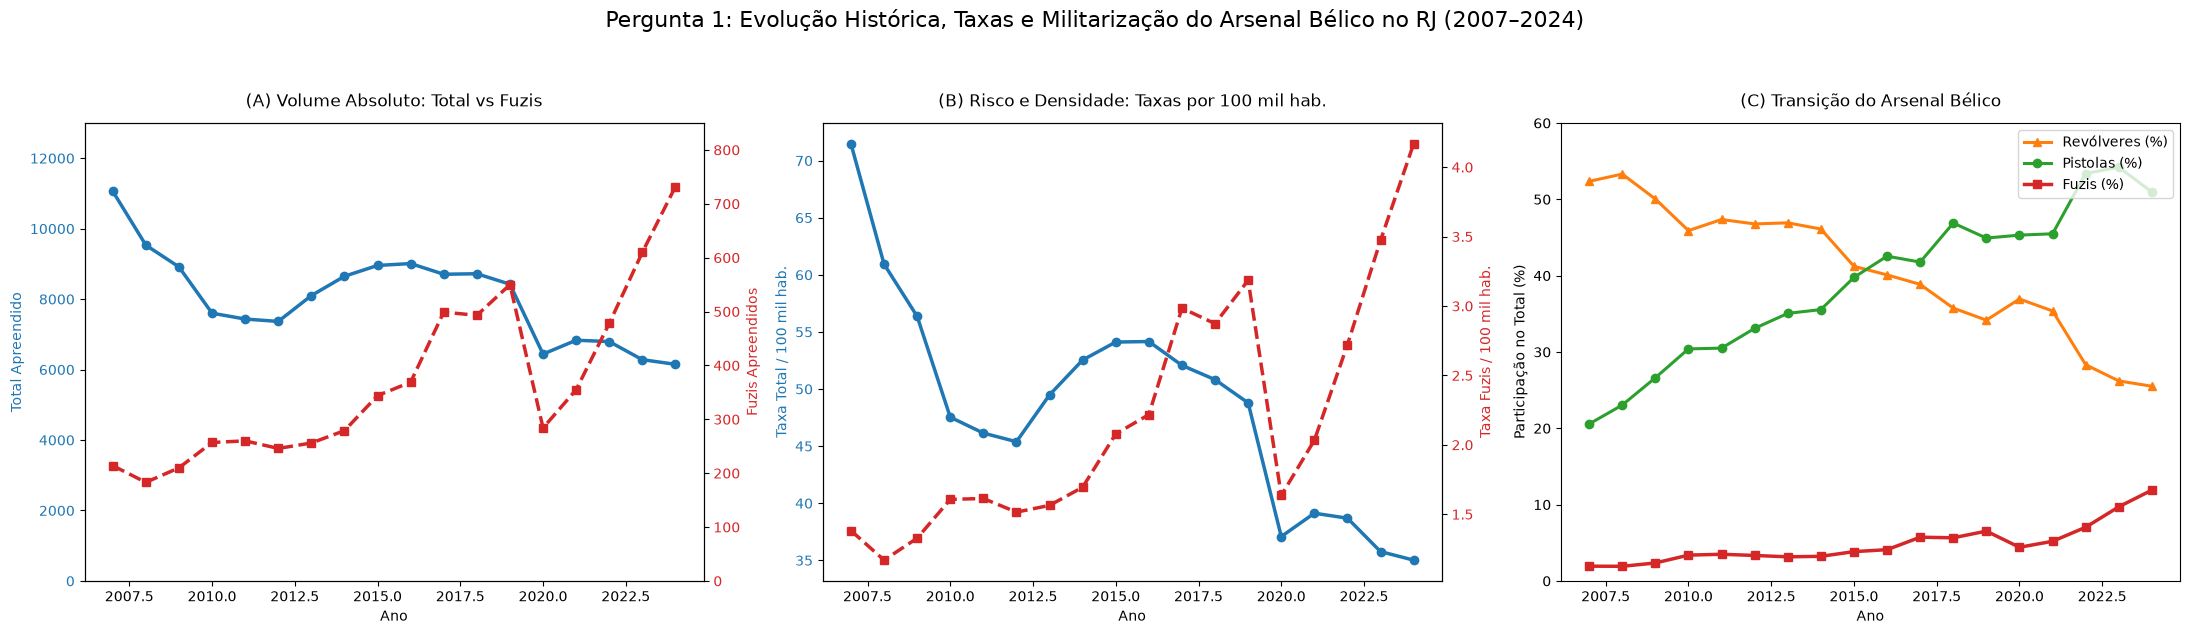

<Figure size 640x480 with 0 Axes>

In [5]:
#######################################################################
#Limpeza dos dados
df_cisp_mensal['regiao'] = df_cisp_mensal['regiao'].replace({
    'Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i': 'Grande Niterói',
    'Grande Niteroi': 'Grande Niterói'
})
df_letalidade['regiao'] = df_letalidade['regiao'].replace({'Grande Niteroi': 'Grande Niterói'})
pop_uf = df_letalidade[df_letalidade['regiao'] == 'Estado'][['ano', 'populacao']].drop_duplicates().set_index('ano')['populacao']
########################################################################
armas_anual = df_armas[df_armas['ano'].between(2007, 2024)].groupby('ano')[['quantidade_arma_fogo_total', 'quantidade_fuzil', 'quantidade_pistola', 'quantidade_revolver']].sum()
armas_anual['populacao'] = pop_uf
armas_anual['populacao'] = armas_anual['populacao'].ffill()

armas_anual['taxa_armas_100k'] = (armas_anual['quantidade_arma_fogo_total'] / armas_anual['populacao']) * 100000
armas_anual['taxa_fuzil_100k'] = (armas_anual['quantidade_fuzil'] / armas_anual['populacao']) * 100000
armas_anual['prop_fuzil_pct'] = (armas_anual['quantidade_fuzil'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_pistola_pct'] = (armas_anual['quantidade_pistola'] / armas_anual['quantidade_arma_fogo_total']) * 100
armas_anual['prop_revolver_pct'] = (armas_anual['quantidade_revolver'] / armas_anual['quantidade_arma_fogo_total']) * 100

#print("Resumo Decenal da Evolução de Armas e Fuzis (Amostra Bienal):")
#display_cols = ['quantidade_arma_fogo_total', 'taxa_armas_100k', 'quantidade_fuzil', 'taxa_fuzil_100k', 'prop_revolver_pct', 'prop_pistola_pct', 'prop_fuzil_pct']
#print(armas_anual.loc[[2007, 2011, 2015, 2019, 2024], display_cols].round(2))

# Expansão para 3 painéis (1x3)
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(22, 6))

color1, color2 = '#1f77b4', '#d62728'

# Painel 1 (ax1): Volumes Absolutos (Seu código original)
ax1.plot(armas_anual.index, armas_anual['quantidade_arma_fogo_total'], marker='o', color=color1, linewidth=2.5, label='Total Armas')
ax1.set_xlabel('Ano')
ax1.set_ylabel('Total Apreendido', color=color1)
ax1.tick_params(axis='y', labelcolor=color1)
ax1.set_ylim(0, 13000)

ax1_twin = ax1.twinx()
ax1_twin.plot(armas_anual.index, armas_anual['quantidade_fuzil'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax1_twin.set_ylabel('Fuzis Apreendidos', color=color2)
ax1_twin.tick_params(axis='y', labelcolor=color2)
ax1_twin.set_ylim(0, 850)
ax1.set_title('(A) Volume Absoluto: Total vs Fuzis', pad=12)

# Painel 2 (ax2): Taxa por 100 mil habitantes (Nova inserção)
ax2.plot(armas_anual.index, armas_anual['taxa_armas_100k'], marker='o', color=color1, linewidth=2.5)
ax2.set_xlabel('Ano')
ax2.set_ylabel('Taxa Total / 100 mil hab.', color=color1)
ax2.tick_params(axis='y', labelcolor=color1)

ax2_twin = ax2.twinx()
ax2_twin.plot(armas_anual.index, armas_anual['taxa_fuzil_100k'], marker='s', color=color2, linewidth=2.5, linestyle='--')
ax2_twin.set_ylabel('Taxa Fuzis / 100 mil hab.', color=color2)
ax2_twin.tick_params(axis='y', labelcolor=color2)
ax2.set_title('(B) Risco e Densidade: Taxas por 100 mil hab.', pad=12)

# Painel 3 (ax3): Proporções (Seu ax2 original)
anos = armas_anual.index
ax3.plot(anos, armas_anual['prop_revolver_pct'], marker='^', color='#ff7f0e', linewidth=2.2, label='Revólveres (%)')
ax3.plot(anos, armas_anual['prop_pistola_pct'], marker='o', color='#2ca02c', linewidth=2.2, label='Pistolas (%)')
ax3.plot(anos, armas_anual['prop_fuzil_pct'], marker='s', color='#d62728', linewidth=2.5, label='Fuzis (%)')
ax3.set_xlabel('Ano')
ax3.set_ylabel('Participação no Total (%)')
ax3.set_ylim(0, 60)
ax3.set_title('(C) Transição do Arsenal Bélico', pad=12)
ax3.legend(frameon=True, facecolor='white', loc='upper right')

plt.suptitle('Pergunta 1: Evolução Histórica, Taxas e Militarização do Arsenal Bélico no RJ (2007–2024)', fontsize=16, y=1.05)
plt.tight_layout()
plt.show()
plt.suptitle('Pergunta 1: Evolução Histórica e Militarização do Arsenal Bélico Apreendido no RJ (2007–2024)', fontsize=14, y=1.02)
plt.show()

## Pergunta 2 

Quais municıpios ou Áreas Integradas (AISP) concentram as maiores taxas proporcionais de letalidade
violenta e feminicıdio?

## Relacionando regiões e aisps 

In [143]:
grupos = df_rel.groupby("regiao")["id_aisp"].unique()

(
    baixadas,
    centro_sul_fluminense,
    costa_verde,
    metropolitana,
    medio_paraiba,
    noroeste_fluminense,
    norte_fluminense,
    serrana
) = grupos.tolist()

print(grupos)

regiao
Baixadas Litorâneas                                           [25, 35, 32]
Centro-Sul Fluminense                                             [10, 38]
Costa Verde                                                           [33]
Metropolitana            [16, 17, 19, 2, 22, 23, 3, 4, 5, 6, 14, 18, 27...
Médio Paraíba                                                 [10, 28, 37]
Noroeste Fluminense                                               [29, 36]
Norte Fluminense                                               [29, 32, 8]
Serrana                                                       [36, 11, 30]
Name: id_aisp, dtype: object


## P2

In [8]:
def baixar_shapefile_github(url: str) -> gpd.GeoDataFrame:
    """Baixa o zip do GitHub, salva num arquivo temporário e lê no GeoPandas."""
    resposta = requests.get(url, timeout=60)
    resposta.raise_for_status() 
    
    with tempfile.NamedTemporaryFile(delete=False, suffix='.zip') as tmp:
        tmp.write(resposta.content)
        tmp_path = tmp.name
        
    try:
        gdf = gpd.read_file(f"zip://{tmp_path}")
    finally:
        os.unlink(tmp_path)
        
    return gdf

def carregar_e_preparar_dados(dataframes: dict) -> dict:
    """Consolida as bases tabulares em memória e lê os shapefiles diretamente do GitHub."""
    # 1. Bases tabulares
    df_armas = dataframes["armas_apreendidas_mensal"]
    df_cisp_mensal = dataframes["evolucao_mensal_cisp"]
    df_mun_mensal = dataframes["evolucao_mensal_municipio"]
    df_taxa_mun_mensal = dataframes["taxa_evolucao_mensal_municipio"]
    df_fem_cisp = dataframes["feminicidio_mensal_cisp"]
    df_letalidade = dataframes["taxa_letalidade"]
    df_policial = dataframes["evolucao_policial_morto_servico_mensal"]
    df_rel = dataframes["relacao_cisp_aisp_risp"]
    
    # 2. Bases espaciais
    base_url = "https://raw.githubusercontent.com/josue-fgv/AEDV-A2-/main/Projeto/Datas"
    print("Baixando shapefiles de forma segura...")
    gdf_cisp = baixar_shapefile_github(f"{base_url}/CISP.zip")
    gdf_risp = baixar_shapefile_github(f"{base_url}/RISP.zip")
    gdf_aisp = baixar_shapefile_github(f"{base_url}/AISP.zip")
    print("Arquivos espaciais carregados com sucesso!")
    
    # 3. Tratamentos e Cruzamentos
    correcao_regiao = {
        "Grande NiterÃƒÂƒÃ‚ÂƒÃƒÂ‚Ã‚Â³i": "Grande Niterói",
        "Grande Niteroi": "Grande Niterói"
    }
    df_cisp_mensal["regiao"] = df_cisp_mensal["regiao"].replace(correcao_regiao)
    df_mun_mensal["regiao"] = df_mun_mensal["regiao"].replace(correcao_regiao)
    df_letalidade["regiao"] = df_letalidade["regiao"].replace(correcao_regiao)

    aisp_names = {
        2: "AISP 02 (Botafogo/Catete)", 3: "AISP 03 (Méier/Jacarezinho)", 4: "AISP 04 (São Cristóvão/Centro)",
        5: "AISP 05 (Praça da Harmonia/Centro)", 6: "AISP 06 (Tijuca/Vila Isabel)", 7: "AISP 07 (São Gonçalo)",
        8: "AISP 08 (Campos dos Goytacazes)", 9: "AISP 09 (Rocha Miranda/Madureira)", 10: "AISP 10 (Barra do Piraí/Valença)",
        11: "AISP 11 (Nova Friburgo)", 12: "AISP 12 (Niterói/Maricá)", 14: "AISP 14 (Bangu/Senador Camará)",
        15: "AISP 15 (Duque de Caxias)", 16: "AISP 16 (Olaria/Penha/Alemão)", 17: "AISP 17 (Ilha do Governador)",
        18: "AISP 18 (Jacarepaguá/CDD)", 19: "AISP 19 (Copacabana)", 20: "AISP 20 (Nova Iguaçu/Mesquita)",
        21: "AISP 21 (São João de Meriti)", 22: "AISP 22 (Maré/Bonsucesso)", 23: "AISP 23 (Leblon/Rocinha)",
        24: "AISP 24 (Queimados/Japeri/Itaguaí)", 25: "AISP 25 (Cabo Frio/Região dos Lagos)", 26: "AISP 26 (Petrópolis)",
        27: "AISP 27 (Santa Cruz/Sepetiba)", 28: "AISP 28 (Volta Redonda/Barra Mansa)", 29: "AISP 29 (Itaperuna/Noroeste)",
        30: "AISP 30 (Teresópolis)", 31: "AISP 31 (Barra da Tijuca/Recreio)", 32: "AISP 32 (Macaé/Rio das Ostras)",
        33: "AISP 33 (Angra dos Reis/Costa Verde)", 34: "AISP 34 (Magé/Guapimirim)", 35: "AISP 35 (Itaboraí/Tanguá)",
        36: "AISP 36 (Santo Antônio de Pádua)", 37: "AISP 37 (Resende/Itatiaia)", 38: "AISP 38 (Três Rios/Paraíba do Sul)",
        39: "AISP 39 (Belford Roxo)", 40: "AISP 40 (Campo Grande)", 41: "AISP 41 (Irajá/Pavuna/Acari)"
    }
    aisp_coords = {
        2: (-43.182, -22.951), 3: (-43.278, -22.902), 4: (-43.218, -22.912), 5: (-43.180, -22.908),
        6: (-43.238, -22.923), 7: (-43.053, -22.826), 8: (-41.324, -21.754), 9: (-43.344, -22.856),
        10: (-43.829, -22.469), 11: (-42.531, -22.281), 12: (-43.103, -22.883), 14: (-43.466, -22.875),
        15: (-43.311, -22.785), 16: (-43.272, -22.842), 17: (-43.208, -22.805), 18: (-43.365, -22.938),
        19: (-43.185, -22.969), 20: (-43.451, -22.759), 21: (-43.372, -22.803), 22: (-43.245, -22.858),
        23: (-43.225, -22.981), 24: (-43.559, -22.716), 25: (-42.028, -22.880), 26: (-43.178, -22.505),
        27: (-43.678, -22.918), 28: (-44.104, -22.523), 29: (-41.889, -21.205), 30: (-42.966, -22.412),
        31: (-43.395, -23.001), 32: (-41.786, -22.371), 33: (-44.318, -23.006), 34: (-43.041, -22.652),
        35: (-42.859, -22.744), 36: (-42.132, -21.539), 37: (-44.447, -22.468), 38: (-43.209, -22.116),
        39: (-43.399, -22.764), 40: (-43.559, -22.902), 41: (-43.332, -22.825)
    }

    aisp_reg_map = df_cisp_mensal[df_cisp_mensal["ano"] >= 2018].groupby("id_aisp")["regiao"].agg(
        lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior"
    ).to_dict()
    aisp_reg_map[39] = "Baixada Fluminense"
    aisp_reg_map[35] = "Grande Niterói"
    
    # 1. Painel Anual por AISP (2007-2024)
    armas_aisp_yr = df_armas[df_armas["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_fuzil", "quantidade_pistola", "quantidade_revolver", "quantidade_arma_fogo_total"]
    ].sum().reset_index()

    crimes_aisp_yr = df_cisp_mensal[df_cisp_mensal["ano"].between(2007, 2024)].groupby(["ano", "id_aisp"])[
        ["quantidade_letalidade_violenta", "quantidade_homicidio_doloso", "quantidade_homicidio_intervencao_policial"]
    ].sum().reset_index()

    df_aisp_anual = pd.merge(armas_aisp_yr, crimes_aisp_yr, on=["ano", "id_aisp"], how="inner")
    df_aisp_anual = df_aisp_anual[df_aisp_anual["id_aisp"].isin(aisp_names.keys())].copy()
    df_aisp_anual["nome_aisp"] = df_aisp_anual["id_aisp"].map(aisp_names)
    df_aisp_anual["regiao"] = df_aisp_anual["id_aisp"].map(aisp_reg_map)
    df_aisp_anual["lon"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][0])
    df_aisp_anual["lat"] = df_aisp_anual["id_aisp"].map(lambda x: aisp_coords[x][1])
    df_aisp_anual["prop_intervencao_pct"] = np.where(
        df_aisp_anual["quantidade_letalidade_violenta"] > 0,
        (df_aisp_anual["quantidade_homicidio_intervencao_policial"] / df_aisp_anual["quantidade_letalidade_violenta"]) * 100,
        0.0
    ).round(1)

    # 2. Evolução Histórica do Arsenal Bélico (2007-2024)
    armas_uf = df_armas[df_armas["ano"].between(2007, 2024)].groupby("ano")[
        ["quantidade_arma_fogo_total", "quantidade_fuzil", "quantidade_pistola", "quantidade_revolver"]
    ].sum().reset_index()
    armas_uf["Revólveres (%)"] = ((armas_uf["quantidade_revolver"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Pistolas (%)"] = ((armas_uf["quantidade_pistola"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Fuzis (%)"] = ((armas_uf["quantidade_fuzil"] / armas_uf["quantidade_arma_fogo_total"]) * 100).round(2)
    armas_uf["Outras Armas (%)"] = (100 - (armas_uf["Revólveres (%)"] + armas_uf["Pistolas (%)"] + armas_uf["Fuzis (%)"])).round(2)
    
    # 3. Cruzamento Municipal Letalidade Violenta vs. Feminicídio (2016-2024)
    taxa_mun_media = (
        df_taxa_mun_mensal[df_taxa_mun_mensal["ano"].between(2016, 2024)]
        .groupby(["ano", "id_municipio"])["taxa_letalidade_violenta"].sum()
        .reset_index()
        .groupby("id_municipio")["taxa_letalidade_violenta"].mean()
        .reset_index()
    )
    m_pop = pd.merge(
        df_taxa_mun_mensal[["ano", "mes", "id_municipio", "taxa_registro_ocorrencia"]],
        df_mun_mensal[["ano", "mes", "id_municipio", "quantidade_registro_ocorrencia", "regiao"]],
        on=["ano", "mes", "id_municipio"]
    )
    m_pop["pop"] = (m_pop["quantidade_registro_ocorrencia"] / m_pop["taxa_registro_ocorrencia"]) * 100000
    pop_mun = m_pop[m_pop["ano"].between(2016, 2024)].groupby("id_municipio").agg(
        populacao=("pop", "mean"),
        regiao=("regiao", lambda x: x.mode()[0] if len(x.mode()) > 0 else "Interior")
    ).reset_index()

    fem_mun = df_fem_cisp[df_fem_cisp["ano"].between(2016, 2024)].groupby("id_municipio")[
        ["quantidade_morte_feminicidio", "quantidade_tentativa_feminicidio"]
    ].sum().reset_index()
    fem_mun["morte_fem_anual"] = fem_mun["quantidade_morte_feminicidio"] / 9.0

    df_mun_comp = pd.merge(taxa_mun_media, pop_mun, on="id_municipio")
    df_mun_comp = pd.merge(df_mun_comp, fem_mun, on="id_municipio")
    df_mun_comp["taxa_feminicidio_100k"] = ((df_mun_comp["morte_fem_anual"] / df_mun_comp["populacao"]) * 100000).round(2)
    df_mun_comp["taxa_letalidade_violenta"] = df_mun_comp["taxa_letalidade_violenta"].round(2)
    df_mun_comp["populacao"] = df_mun_comp["populacao"].round(0).astype(int)

    mun_nomes = {
        3304557: "Rio de Janeiro", 3301702: "Duque de Caxias", 3304904: "São Gonçalo", 3303500: "Nova Iguaçu",
        3300456: "Belford Roxo", 3305109: "São João de Meriti", 3303302: "Niterói", 3301009: "Campos dos Goytacazes",
        3300704: "Cabo Frio", 3302403: "Macaé", 3302007: "Itaguaí", 3302270: "Japeri", 3304144: "Queimados",
        3302700: "Maricá", 3302502: "Magé", 3300100: "Angra dos Reis", 3305505: "Saquarema", 3300209: "Araruama",
        3306305: "Volta Redonda", 3303906: "Petrópolis", 3303401: "Nova Friburgo", 3302858: "Mesquita",
        3303203: "Nilópolis", 3304524: "Rio das Ostras", 3305554: "Seropédica", 3305208: "São Pedro da Aldeia",
        3301900: "Itaboraí", 3306008: "Três Rios", 3304201: "Resende", 3300407: "Barra Mansa",
        3304755: "S. Francisco de Itabapoana", 3300803: "Cachoeiras de Macacu", 3302205: "Itaperuna",
        3305802: "Teresópolis", 3306107: "Valença", 3300308: "Barra do Piraí", 3301876: "Guapimirim"
    }
    df_mun_grandes = df_mun_comp[df_mun_comp["populacao"] > 50000].copy()
    df_mun_grandes["nome_municipio"] = df_mun_grandes["id_municipio"].map(mun_nomes).fillna(df_mun_grandes["id_municipio"].astype(str))

    # 4. Matriz de Sazonalidade Mensal
    sazonal = df_cisp_mensal[df_cisp_mensal["ano"].between(2003, 2024)].groupby(["regiao", "mes"])["quantidade_letalidade_violenta"].sum().unstack()
    sazonal_index = (sazonal.div(sazonal.mean(axis=1), axis=0) * 100).round(2)
    sazonal_index.columns = ["Jan", "Fev", "Mar", "Abr", "Mai", "Jun", "Jul", "Ago", "Set", "Out", "Nov", "Dez"]

    df_let_reg = df_letalidade[df_letalidade["delito"] == "Letalidade Violenta"].sort_values("ano").copy()

    return {
        "aisp_anual": df_aisp_anual,
        "armas_uf": armas_uf,
        "municipios": df_mun_grandes,
        "sazonal_index": sazonal_index,
        "regional_series": df_let_reg,
        'armas': df_armas,
        'cisp_mensal': df_cisp_mensal,
        'mun_mensal': df_mun_mensal,
        'taxa_mun_mensal': df_taxa_mun_mensal,
        'fem_cisp': df_fem_cisp,
        'letalidade': df_letalidade,
        'policial': df_policial,
        'relacao': df_rel,
        'geo_cisp': gdf_cisp,
        'geo_risp': gdf_risp,
        'geo_aisp': gdf_aisp
    }
    

In [6]:
def criar_fig2_mapa_poligonos_animado(df_aisp_anual: pd.DataFrame, gdf_aisp: gpd.GeoDataFrame):
    # 1. Padronizar a chave de cruzamento
    if 'aisp' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'aisp': 'id_aisp'})
    elif 'AISP' in gdf_aisp.columns:
        gdf_aisp = gdf_aisp.rename(columns={'AISP': 'id_aisp'})

    # Forçar WGS 84 (Latitude/Longitude) e simplificar a malha
    if gdf_aisp.crs is None or gdf_aisp.crs.to_epsg() != 4326:
        gdf_aisp = gdf_aisp.to_crs(epsg=4326)
    
    gdf_aisp.geometry = gdf_aisp.geometry.simplify(tolerance=0.01)
    
    # Definir o ID como índice para a ligação com o Plotly
    gdf_aisp = gdf_aisp.set_index("id_aisp")

    # 2. Isolar os dados tabulares (dinâmicos) sem multiplicar a geometria
    df_anim = df_aisp_anual[df_aisp_anual["ano"].between(2018, 2024)].copy()
    df_anim = df_anim.sort_values(["ano", "id_aisp"])

   # 3. Geração do Mapa Coroplético Animado (Agora associado à métrica criminal)
    fig = px.choropleth_map(
        df_anim,
        geojson=gdf_aisp.geometry,
        locations="id_aisp",
        color="quantidade_letalidade_violenta",  # A cor passa a refletir o volume do crime
        color_continuous_scale="Reds",           # Escala térmica
        range_color=[0, df_anim["quantidade_letalidade_violenta"].max()], # Fixa a legenda para a animação
        animation_frame="ano",           
        hover_name="nome_aisp",
        hover_data={
            "id_aisp": False,
            "regiao": True,                      # Mantém a região visível no hover
            "quantidade_letalidade_violenta": True,
            "quantidade_fuzil": True
        },
        center={"lat": -22.55, "lon": -43.15},
        zoom=7.4,
        map_style="carto-positron",
        title="<b>Evolução Espaço-Temporal da Letalidade Violenta (Polígonos das AISPs)</b>"
    )

    fig.update_traces(marker_opacity=0.75, marker_line_width=0.5)
    fig.update_layout(height=650, margin=dict(l=20, r=20, t=80, b=20))
    
    return fig

In [9]:
if __name__ == "__main__":
    print("Carregando e processando bases do ISP-RJ...")
    dados = carregar_e_preparar_dados(dataframes)

    print("Gerando visualizações...")
    
    fig2 = criar_fig2_mapa_poligonos_animado(dados["aisp_anual"], dados["geo_aisp"])
    fig2.show()

Carregando e processando bases do ISP-RJ...
Baixando shapefiles de forma segura...
Arquivos espaciais carregados com sucesso!
Gerando visualizações...


## Top 10 aisps em homicídios e suas regiões tasosjfhseofwenofwnefonweo

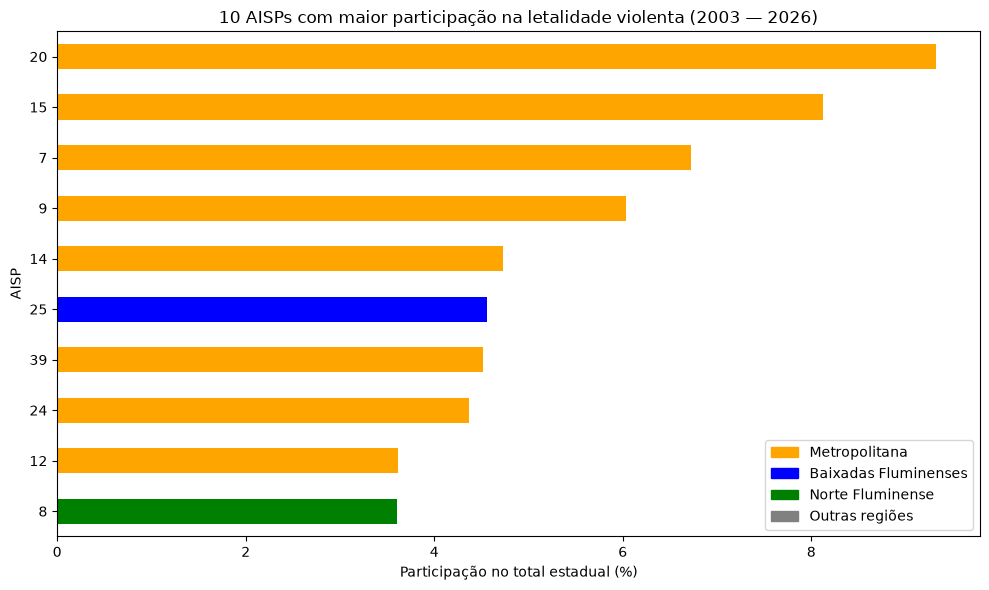

In [144]:
#Este bloco de codigo define as top 10 aisps com mais letalidades violentas. 
mortes_aisp = (
    df_cisp_mensal.groupby("id_aisp")["quantidade_letalidade_violenta"] 
    .sum()
    .sort_values(ascending=False)
)

total_mortes = df_cisp_mensal["quantidade_letalidade_violenta"].sum()

percentual_aisp = (mortes_aisp / total_mortes) * 100


###########################################################################
#Este bloco cria um bar plot das top 10 aisp com mais homicidios e as segmenta por cor pelas sua respectivas regioes.
dados = percentual_aisp.head(10).sort_values()


legenda = [
    Patch(color='orange', label='Metropolitana'),
    Patch(color='blue', label='Baixadas Fluminenses'),
    Patch(color='green', label='Norte Fluminense'),
    Patch(color='gray', label='Outras regiões')
]

cores = [
    'orange' if aisp in metropolitana else 
    'blue' if aisp in baixadas else
    'green' if aisp in norte_fluminense else
    'gary' for aisp in dados.index
]    
percentual_aisp.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    color = cores 
    
)

plt.legend(handles=legenda, loc='lower right')

plt.title("10 AISPs com maior participação na letalidade violenta (2003 — 2026)")
plt.xlabel("Participação no total estadual (%)")
plt.ylabel("AISP")
plt.tight_layout()
plt.show()

## A variação da letalidade violenta das 3 regioes que aparecem no top 10

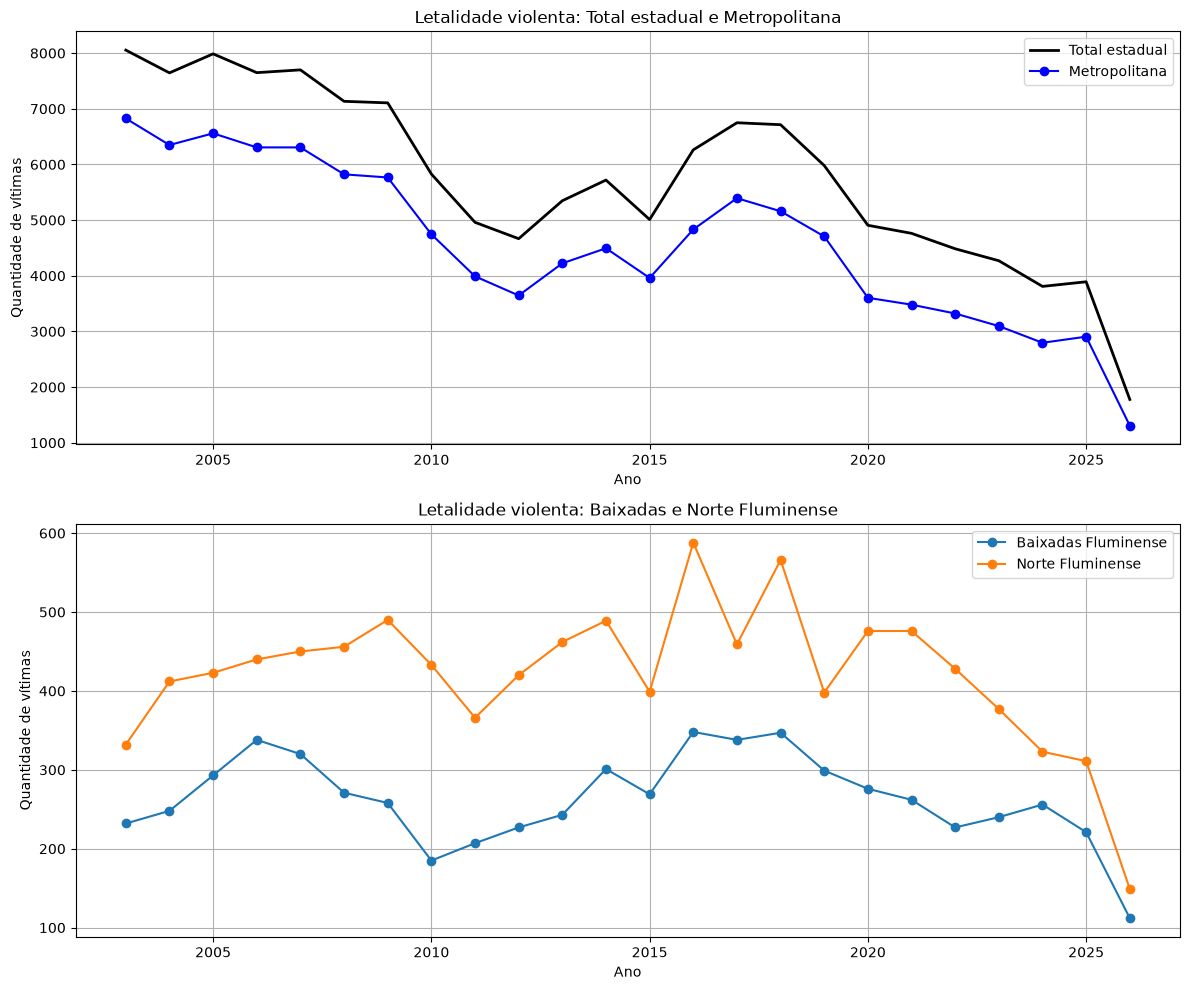

In [147]:
#Letalidade total por ano
letalidades_ano = (
    df_cisp_mensal
    .groupby("ano")["quantidade_letalidade_violenta"]
    .sum()
)

#Criando uma cópia
copia_cisp_mensal = df_cisp_mensal.copy()

#Dicionário de regiões
regioes = {
    "Baixadas Fluminense": baixadas,
    "Centro-Sul Fluminense": centro_sul_fluminense,
    "Costa Verde": costa_verde,
    "Metropolitana": metropolitana,
    "Médio Paraíba": medio_paraiba,
    "Noroeste Fluminense": noroeste_fluminense,
    "Norte Fluminense": norte_fluminense,
    "Serrana": serrana
}

#Associando cada AISP à região
for nome, aisps in regioes.items():
    copia_cisp_mensal.loc[
        copia_cisp_mensal["id_aisp"].isin(aisps),
        "regiao"
    ] = nome

#Agrupando por ano e região
cisp_mensal_por_regiao = (
    copia_cisp_mensal
    .groupby(["ano", "regiao"])["quantidade_letalidade_violenta"]
    .sum()
    .unstack("regiao")
)

#Selecionando as três regiões
top_3 = cisp_mensal_por_regiao[
    ["Metropolitana", "Baixadas Fluminense", "Norte Fluminense"]
]

fig, (ax1, ax2) = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(12, 10)
)

# Gráfico 1: Total estadual e Metropolitana
ax1.plot(
    letalidades_ano.index,
    letalidades_ano.values,
    label="Total estadual",
    color="black",
    linewidth=2
)

ax1.plot(
    cisp_mensal_por_regiao.index,
    cisp_mensal_por_regiao["Metropolitana"],
    label="Metropolitana",
    color="blue",
    marker="o"
)

ax1.set_title("Letalidade violenta: Total estadual e Metropolitana")
ax1.set_xlabel("Ano")
ax1.set_ylabel("Quantidade de vítimas")
ax1.legend()
ax1.grid(True)


# Gráfico 2: Demais regiões do Top 3
for regiao in ["Baixadas Fluminense", "Norte Fluminense"]:
    ax2.plot(
        cisp_mensal_por_regiao.index,
        cisp_mensal_por_regiao[regiao],
        label=regiao,
        marker="o"
    )

ax2.set_title("Letalidade violenta: Baixadas e Norte Fluminense")
ax2.set_xlabel("Ano")
ax2.set_ylabel("Quantidade de vítimas")
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()



In [146]:
df_cisp_mensal

,ano,mes,id_cisp,id_aisp,id_risp,id_municipio,regiao,quantidade_homicidio_doloso,quantidade_latrocinio,quantidade_lesao_corporal_morte,...,quantidade_cmp,quantidade_cmba,quantidade_ameaca,quantidade_pessoas_desaparecidas,quantidade_encontro_cadaver,quantidade_encontro_ossada,quantidade_policial_militar_morto_servico,quantidade_policial_civil_morto_servico,quantidade_registro_ocorrencia,tipo_fase
0,2003,9,1,5,1,3304557,Capital,1,0,0,...,NaN,NaN,19,1,0,0,0,0,656,Consolidado com errata
1,2003,12,1,5,1,3304557,Capital,1,0,0,...,NaN,NaN,21,4,1,0,0,0,725,Consolidado com errata
2,2003,6,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,21,3,0,0,0,0,587,Consolidado com errata
3,2003,11,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,29,0,0,0,0,0,760,Consolidado com errata
4,2003,3,1,5,1,3304557,Capital,0,0,0,...,NaN,NaN,20,1,0,0,0,0,573,Consolidado com errata
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
37994,2026,5,99,37,5,3302254,Interior,4,0,0,...,5.0,0.0,16,0,0,0,0,0,161,Consolidado sem errata
37995,2026,4,99,37,5,3302254,Interior,1,0,0,...,0.0,0.0,14,8,0,0,0,0,134,Consolidado sem errata
37996,2026,3,99,37,5,3302254,Interior,1,0,0,...,3.0,2.0,20,0,0,0,0,0,153,Consolidado com errata
37997,2026,1,99,37,5,3302254,Interior,2,0,0,...,5.0,0.0,33,0,0,0,0,0,175,Consolidado com errata
